# Uczenie głębokie — Zajęcia 4

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kubzal/wsb-merito/blob/main/notebooks/semestr_zimowy_2026_27/uczenie_glebokie/zajecia_4.ipynb)

Pełne notatki do zajęć znajdziesz na [stronie przedmiotu](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/uczenie_glebokie/zajecia_4/). Ten notebook zawiera wszystkie przykłady z notatek, gotowe do uruchomienia.


## Od regresji logistycznej do sztucznego neuronu

Na poprzednich zajęciach regresja logistyczna wygrała (albo zremisowała)
z modelami, które wyglądały na sprytniejsze, i obiecaliśmy, że okaże się
pierwszym krokiem do sieci neuronowych. Dziś rozbieramy ją na części. Zobaczysz,
że w środku są tylko **wagi**, jedna **suma** i jedna **funkcja** — i że
dokładnie tak samo wygląda **sztuczny neuron**, cegiełka, z której zbudowane są
wszystkie sieci neuronowe, od rozpoznawania twarzy po ChatGPT.

Potem odpowiemy na pytanie, którego do tej pory nie zadawaliśmy: **jak model
się uczy?** Co tak naprawdę dzieje się w środku `fit`? Na koniec zbudujemy ten
sam neuron od zera w **PyTorch** — bibliotece, w której od teraz będziemy
budować sieci.

Po dzisiejszych zajęciach będziesz w stanie:

- odczytać wagi i bias wytrenowanej regresji logistycznej i powiedzieć, co
  znaczą,
- policzyć ręcznie w numpy prawdopodobieństwo, które zwraca model,
- wyjaśnić, czym jest sztuczny neuron i funkcja aktywacji,
- wyjaśnić, czym jest funkcja straty i jak spadek gradientu poprawia wagi,
- zbudować i wytrenować jeden neuron w PyTorch i odczytać krzywą uczenia,
- rozpoznać na wykresie za mały i za duży współczynnik uczenia.

> ℹ️ **Godzinę temu na Data Science w Pythonie**
>
> Grupowaliśmy i łączyliśmy dane MeritoBanku. Wyszło m.in., że odsetek
> niespłaconych kredytów rośnie z każdym kolejnym kredytem, który klient już
> spłaca, a opóźnienia w ostatnim roku są ważniejsze niż cel kredytu. W zadaniu
> zobaczysz, czy neuron doszedł do tych samych wniosków — tyle że zapisanych
> w postaci wag.


## Plan na dziś

| Blok | Czas |
|---|---|
| Regresja logistyczna pod lupą — wagi, bias, sigmoida | 10 min |
| Sztuczny neuron | 5 min |
| Jak neuron się uczy — funkcja straty i spadek gradientu | 12 min |
| Neuron w PyTorch | 15 min |
| Współczynnik uczenia i czego jeden neuron nie umie | 3 min |
| **Zadanie 4** | **45 min** |


## Regresja logistyczna pod lupą

### Dane

Pracujemy na siłowni z zajęć 2 — przewidujemy, czy klient zrezygnuje,
na podstawie pięciu cech liczbowych. Dzielimy dane i skalujemy jak na zajęciach
3, tylko tym razem **bez** pipeline: za chwilę zajrzymy modelowi do środka
i chcemy mieć przeskalowane liczby pod ręką.

In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

URL = "https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/uczenie_glebokie/dane/silownia_czyste.csv"
df = pd.read_csv(URL)

cechy = ["wiek", "oplata_mies", "staz_mies", "wizyty_mies", "zgloszenia"]
X = df[cechy]
y = df["zrezygnowal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

### Wagi i bias

In [2]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train_s, y_train)

wagi = pd.Series(model.coef_[0], index=cechy)
print(wagi.sort_values().round(3))
print("bias:", model.intercept_[0].round(3))

wizyty_mies   -0.853
staz_mies     -0.609
wiek          -0.157
oplata_mies    0.348
zgloszenia     0.418
dtype: float64
bias: -1.488


Tak wygląda cała „wiedza" wytrenowanego modelu — pięć **wag** (`coef_`), po
jednej na cechę, i jeden **bias** (`intercept_`, wyraz wolny). Nic więcej
w środku nie ma.

Jak czytać wagi:

- **Znak** mówi o kierunku. Ujemna waga — im więcej tej cechy, tym **mniejsze**
  ryzyko rezygnacji. Dodatnia — tym większe. Więcej wizyt i dłuższy staż
  chronią przed odejściem, więcej zgłoszeń i wyższa opłata — zwiększają ryzyko.
- **Wielkość** mówi o sile. Ponieważ cechy są przeskalowane, każda waga mówi,
  co się dzieje, gdy cecha rośnie o jedno odchylenie standardowe — więc wagi
  można porównywać między sobą. Wizyty (−0.85) liczą się najbardziej, wiek
  (−0.16) prawie wcale. Dokładnie to widzieliśmy na wykresach na zajęciach 3
  z DS w Pythonie.

> ⚠️ **Bez skalowania wag nie porównasz**
>
> Gdyby model był trenowany na surowych danych, waga wieku dotyczyłaby jednego
> roku, a waga opłaty — jednej złotówki. Porównywanie ich byłoby jak
> porównywanie ceny w groszach z ceną w tysiącach. Kolejny powód, żeby
> skalowanie było zawsze pierwszym krokiem.

### Model policzony ręcznie

Na zajęciach 3 regresja logistyczna działała w trzech krokach: ważona suma cech,
„ściśnięcie" do przedziału 0–1 i próg 0.5. Sprawdźmy to na pierwszym kliencie
ze zbioru testowego. Najpierw kim jest:

In [3]:
X_test.iloc[0]

wiek            51.0
oplata_mies    139.0
staz_mies       13.0
wizyty_mies      1.6
zgloszenia       1.0
Name: 1427, dtype: float64

Klient od 13 miesięcy, przychodzi półtora raza w miesiącu. Liczymy:

In [4]:
klient = X_test_s[0]

z = (klient * wagi.values).sum() + model.intercept_[0]   # 1. ważona suma + bias
p = 1 / (1 + np.exp(-z))                                 # 2. ściśnięcie do 0–1

print("z =", round(z, 3), "  p =", round(p, 3))
print("predict_proba:", model.predict_proba(X_test_s[:1]).round(3))

z = 0.125   p = 0.531
predict_proba: [[0.469 0.531]]


Wyszło co do trzeciego miejsca po przecinku to samo, co zwraca `predict_proba`
(druga kolumna to prawdopodobieństwo klasy 1). p = 0.531 > 0.5, więc model
przewiduje rezygnację — i ma rację, ten klient rzeczywiście odszedł.

Która cecha zaważyła? Wystarczy rozpisać sumę na składniki:

In [5]:
wklad = pd.Series(klient * wagi.values, index=cechy)
wklad.sort_values().round(3)

wiek          -0.294
oplata_mies    0.076
zgloszenia     0.098
staz_mies      0.647
wizyty_mies    1.087
dtype: float64

Półtorej wizyty w miesiącu to dużo poniżej średniej, a ujemna waga razy ujemna
(przeskalowana) wartość daje duży **plus** — ponad +1 do sumy. Krótki staż
dorzuca kolejne +0.65. Wiek (51 lat, powyżej średniej) trochę ryzyko obniżył.
Tak model „tłumaczy się" ze swojej decyzji.

### Sigmoida

Funkcja z kroku 2, `1 / (1 + e^(−z))`, nazywa się **sigmoidą** (*sigmoid*,
od kształtu litery S). Zobaczmy ją:

Text(0, 0.5, 'prawdopodobieństwo klasy 1')

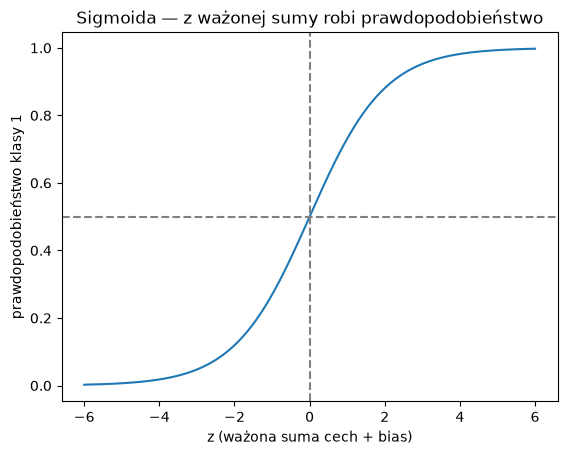

In [6]:
import matplotlib.pyplot as plt

z = np.linspace(-6, 6, 200)
plt.plot(z, 1 / (1 + np.exp(-z)))
plt.axhline(0.5, color="gray", linestyle="--")
plt.axvline(0, color="gray", linestyle="--")
plt.title("Sigmoida — z ważonej sumy robi prawdopodobieństwo")
plt.xlabel("z (ważona suma cech + bias)")
plt.ylabel("prawdopodobieństwo klasy 1")

| z | p | Znaczenie |
|---|---|---|
| −4 | 0.018 | model jest pewien, że klasa 0 |
| 0 | 0.5 | model nie ma pojęcia |
| 0.125 | 0.531 | nasz klient — „raczej odejdzie" |
| 4 | 0.982 | model jest pewien, że klasa 1 |

Ważona suma może wyjść dowolna — −100 albo 37. Sigmoida każdą liczbę zamienia na
wartość między 0 a 1, którą da się czytać jak prawdopodobieństwo. Próg 0.5
odpowiada dokładnie z = 0.


## Sztuczny neuron

Narysujmy to, co właśnie policzyliśmy:

```text
  wejścia            wagi

  wiek        ───  × −0.16  ──┐
  oplata_mies ───  × +0.35  ──┤
  staz_mies   ───  × −0.61  ──┼──▶  Σ + bias  ──▶  sigmoida  ──▶  p = 0.531
  wizyty_mies ───  × −0.85  ──┤       (z)        (aktywacja)
  zgloszenia  ───  × +0.42  ──┘
```

To jest **sztuczny neuron**. Dostaje kilka liczb na wejściu, każdą mnoży przez
jej wagę, sumuje, dodaje bias i przepuszcza wynik przez **funkcję aktywacji**.
Regresja logistyczna to po prostu jeden neuron z sigmoidą jako aktywacją.

Ten sam obiekt ma w dwóch światach różne nazwy:

| Statystyka / scikit-learn | Sieci neuronowe |
|---|---|
| współczynniki (`coef_`) | **wagi** (*weights*) |
| wyraz wolny (`intercept_`) | **bias** |
| funkcja logistyczna | **funkcja aktywacji** (tu: sigmoida) |
| regresja logistyczna | **jeden neuron** |
| `fit` | **trening** |

> 📝 **Skąd nazwa**
>
> Pomysł pochodzi z lat 50. i jest luźno wzorowany na komórce nerwowej:
> neuron w mózgu zbiera sygnały od innych neuronów, część z nich wzmacnia,
> część osłabia, i jeśli suma jest dość duża — „odpala". Na tym podobieństwo
> się kończy, ale nazwa została.

**Sieć neuronowa** to wiele takich neuronów połączonych w warstwy — wyjścia
jednych są wejściami kolejnych. Zbudujemy ją na następnych zajęciach. Wszystko,
czego dziś nauczymy się o jednym neuronie, przeniesie się na sieć bez zmian.


## Jak neuron się uczy

Na razie wagi dostaliśmy gotowe od scikit-learn. Ale skąd `fit` wie, że waga
wizyt ma wynosić −0.85, a nie +3? Odpowiedź ma dwie części: **funkcję straty**
i **spadek gradientu**.

### Funkcja straty — jak bardzo model się myli

Żeby model mógł się poprawiać, potrzebuje jednej liczby, która mówi, jak
bardzo jest źle. Accuracy się do tego nie nadaje — model, który klientowi,
który odszedł, daje p = 0.51, i model, który daje mu p = 0.99, mają tę samą
accuracy. A przecież drugi jest dużo lepszy.

Dla klasyfikacji używa się **straty logarytmicznej** (*log loss*, w sieciach
neuronowych zwanej **binarną entropią krzyżową**, *binary cross-entropy*, BCE).
Dla każdego przykładu patrzy, jakie prawdopodobieństwo model dał **prawdziwej**
klasie, i karze tym mocniej, im mniejsze ono było:

| Klient odszedł (y = 1), model mówi p = | Kara −log(p) |
|---|---|
| 0.99 | 0.01 |
| 0.9 | 0.11 |
| 0.5 | 0.69 |
| 0.1 | 2.30 |
| 0.01 | 4.61 |

Strata całego modelu to średnia kar ze wszystkich przykładów. Najważniejsze:
kara rośnie gwałtownie za **pewną siebie pomyłkę**. Model, który mówi „na 99%
zostanie" o kliencie, który odszedł, płaci prawie pięć razy więcej niż model,
który uczciwie mówi „nie wiem".

In [7]:
from sklearn.metrics import log_loss

p_train = model.predict_proba(X_train_s)[:, 1]
print("nasz model:        ", round(log_loss(y_train, p_train), 3))
print("zawsze mówi 0.5:   ", round(log_loss(y_train, np.full(len(y_train), 0.5)), 3))

nasz model:         0.459
zawsze mówi 0.5:    0.693


**Trening to szukanie takich wag, przy których strata jest jak najmniejsza.**
Model „bez zdania" (wszystkie wagi zero, zawsze p = 0.5) ma stratę 0.693 —
od tego punktu zaczniemy.

### Spadek gradientu — w dół po omacku

Wyobraź sobie, że stoisz na zboczu góry w gęstej mgle i chcesz zejść do
doliny. Nie widzisz jej, ale czujesz pod stopami, w którą stronę teren opada.
Robisz krok w tamtą stronę, znowu sprawdzasz nachylenie, znowu krok. Po wielu
krokach jesteś na dole.

To jest **spadek gradientu** (*gradient descent*):

- **położenie** to aktualne wagi,
- **wysokość** to strata dla tych wag,
- **nachylenie pod stopami** to **gradient** — dla każdej wagi mówi, w którą
  stronę i jak mocno zmienia się strata, gdy tę wagę trochę ruszyć,
- **długość kroku** to **współczynnik uczenia** (*learning rate*, `lr`).

![Spadek gradientu — strata w zależności od jednej wagi i kolejne kroki](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/uczenie_glebokie/obrazki/zajecia_4_spadek_gradientu.png)

Na wykresie strata zależy od jednej wagi — wagi wizyt (pozostałe stoją
w miejscu). Startujemy wysoko na zboczu, od wagi 2.5, i schodzimy. Po lewej
rozsądny krok: na stromym zboczu kroki są duże, przy dnie coraz mniejsze — bo
gradient maleje, gdy teren się wypłaszcza — i po kilku krokach jesteśmy przy
dnie (−0.86). Po prawej krok jest za długi: pierwszy skok przerzuca model przez
dolinę daleko na drugie zbocze. Tu jeszcze udało się wrócić, ale przy jeszcze
dłuższym kroku model odbijałby się od zbocza do zbocza coraz wyżej — zobaczysz
to za chwilę w PyTorch.

### Cały trening w pięciu linijkach

Dla jednego neuronu gradient da się zapisać prostym wzorem. Nie musisz go
wyprowadzać — to wynik rachunku różniczkowego, a za chwilę PyTorch policzy go
za nas sam. Ale warto raz zobaczyć, że w środku `fit` nie ma żadnej magii:

In [8]:
w = np.zeros(5)   # start: wszystkie wagi zero
b = 0.0
lr = 0.5

for krok in range(1000):
    p = 1 / (1 + np.exp(-(X_train_s @ w + b)))   # 1. przewidywania dla wszystkich
    blad = p - y_train.values                     # 2. o ile się pomylił
    w = w - lr * X_train_s.T @ blad / len(blad)   # 3. krok w dół zbocza
    b = b - lr * blad.mean()

print(pd.Series(w, index=cechy).round(3))
print("bias:", round(b, 3))

wiek          -0.158
oplata_mies    0.351
staz_mies     -0.614
wizyty_mies   -0.863
zgloszenia     0.421
dtype: float64
bias: -1.493


Te same wagi co ze scikit-learn, z dokładnością do setnych. `@` to mnożenie
macierzy — ważona suma cech policzona dla wszystkich 1187 klientów naraz.

> 📝 **Dlaczego nie co do tysięcznej?**
>
> `LogisticRegression` domyślnie lekko „przytrzymuje" wagi przy zerze —
> to tzw. **regularyzacja**, która chroni przed przeuczeniem. Dlatego jego
> wagi są minimalnie mniejsze. Do regularyzacji wrócimy na zajęciach 6.


## Neuron w PyTorch

Ręczny wzór na gradient działa dla jednego neuronu. Sieć do rozpoznawania
obrazów ma miliony wag w dziesiątkach warstw — tam nikt nie wyprowadza wzorów
ręcznie. Biblioteki do głębokiego uczenia robią dwie rzeczy, których numpy nie
umie: **same liczą gradienty** i potrafią liczyć na **karcie graficznej**.

Najpopularniejsza z nich to **PyTorch** (rozwijany przez Metę). W Colabie jest
zainstalowany od razu.

> 📝 **A Keras i TensorFlow?**
>
> To druga popularna rodzina bibliotek (od Google). Keras ukrywa pętlę
> treningową w jednym `model.fit(...)`, jak scikit-learn. My wybieramy PyTorch
> właśnie dlatego, że pętlę widać — rozumiesz, co się dzieje w każdym kroku.
> Kto zrozumie PyTorch, przesiądzie się na Keras w jedno popołudnie.

### Tensory

PyTorch nie pracuje na DataFrame'ach ani tablicach numpy, tylko na
**tensorach**. Tensor to praktycznie to samo co tablica numpy — tabela liczb —
tylko z dwoma supermocami z akapitu wyżej.

In [9]:
import torch
from torch import nn

X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)
X_test_t = torch.tensor(X_test_s, dtype=torch.float32)

print(X_train_t.shape, y_train_t.shape)

torch.Size([1187, 5]) torch.Size([1187, 1])


- `dtype=torch.float32` — sieci liczą na liczbach zmiennoprzecinkowych
  pojedynczej precyzji. To wystarczająco dokładne i dwa razy szybsze.
- `.view(-1, 1)` zamienia listę 1187 zer i jedynek w **kolumnę** 1187 × 1 —
  bo model zwraca jedną liczbę na klienta, czyli też kolumnę, i obie muszą mieć
  ten sam kształt.

### Model

In [10]:
torch.manual_seed(42)

neuron = nn.Sequential(
    nn.Linear(5, 1),   # ważona suma 5 cech + bias
    nn.Sigmoid(),      # aktywacja: ściśnięcie do 0–1
)
neuron

Sequential(
  (0): Linear(in_features=5, out_features=1, bias=True)
  (1): Sigmoid()
)

Dokładnie nasz rysunek neuronu, zapisany w kodzie:

- `nn.Linear(5, 1)` — **5 wejść, 1 wyjście**. W środku 5 wag i 1 bias.
- `nn.Sigmoid()` — funkcja aktywacji.
- `nn.Sequential` — skleja kroki jeden po drugim, jak `make_pipeline`.

`torch.manual_seed(42)` działa jak `random_state` — na starcie wagi są
**losowe**, a ziarno sprawia, że za każdym razem te same.

### Pętla treningowa

W scikit-learn trening to `fit`. W PyTorch piszemy go sami — i to jest ten sam
spadek gradientu co w numpy, tylko gradient liczy się sam:

In [11]:
funkcja_straty = nn.BCELoss()
optymalizator = torch.optim.SGD(neuron.parameters(), lr=0.5)

historia = []
for epoka in range(200):
    optymalizator.zero_grad()                # 1. wyzeruj gradienty z poprzedniego kroku
    p = neuron(X_train_t)                    # 2. przewidywania
    strata = funkcja_straty(p, y_train_t)    # 3. jak bardzo źle
    strata.backward()                        # 4. policz gradienty (sam!)
    optymalizator.step()                     # 5. krok w dół zbocza
    historia.append(strata.item())

print("strata na początku:", round(historia[0], 3), " na końcu:", round(historia[-1], 3))

strata na początku: 0.798  na końcu: 0.459


Pięć kroków, które od teraz będą w **każdej** pętli treningowej, aż do końca
semestru:

| Krok | Kod | Odpowiednik w numpy |
|---|---|---|
| 1. wyzeruj gradienty | `optymalizator.zero_grad()` | — (PyTorch domyślnie je sumuje) |
| 2. przewidywania | `p = neuron(X_train_t)` | `p = 1 / (1 + np.exp(-(X @ w + b)))` |
| 3. strata | `strata = funkcja_straty(p, y_train_t)` | `log_loss(...)` |
| 4. gradienty | `strata.backward()` | wzór `X.T @ blad / n` |
| 5. krok | `optymalizator.step()` | `w = w - lr * gradient` |

Słowniczek:

- **epoka** — jedno przejście przez cały zbiór treningowy. Tu każda epoka to
  jeden krok, bo liczymy na wszystkich 1187 klientach naraz.
- `nn.BCELoss()` — binarna entropia krzyżowa, czyli ta sama strata
  logarytmiczna co w `log_loss`. Strata 0.459 na końcu to ta sama liczba, którą
  scikit-learn osiągnął swoim `fit`.
- `torch.optim.SGD` — optymalizator, czyli „ten, który robi kroki". SGD to
  zwykły spadek gradientu. Lepsze optymalizatory poznamy na zajęciach 6.
- `.item()` wyjmuje z jednoelementowego tensora zwykłą liczbę Pythona.

### Krzywa uczenia

Historia straty to pierwsza rzecz, na którą patrzy się po treningu sieci:

Text(0, 0.5, 'strata (BCE)')

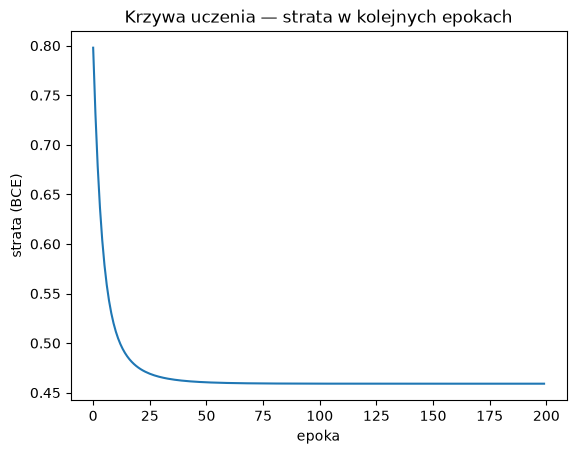

In [12]:
plt.plot(historia)
plt.title("Krzywa uczenia — strata w kolejnych epokach")
plt.xlabel("epoka")
plt.ylabel("strata (BCE)")

Najpierw szybki spadek — wagi są losowe i łatwo je poprawić. Potem krzywa się
wypłaszcza: jesteśmy na dnie doliny i kolejne kroki prawie nic nie zmieniają.
Wypłaszczenie to sygnał, że dalszy trening nic nie da.

### Ocena — ten sam model co w scikit-learn?

Przewidujemy dla zbioru testowego. `torch.no_grad()` mówi PyTorch, że teraz
tylko liczymy, a nie trenujemy — więc nie musi przygotowywać gradientów:

In [13]:
from sklearn.metrics import accuracy_score, f1_score

with torch.no_grad():
    p_test = neuron(X_test_t).numpy().ravel()

y_pred = (p_test > 0.5).astype(int)
print("PyTorch       accuracy", round(accuracy_score(y_test, y_pred), 3), "  F1", round(f1_score(y_test, y_pred), 3))

y_pred_sk = model.predict(X_test_s)
print("scikit-learn  accuracy", round(accuracy_score(y_test, y_pred_sk), 3), "  F1", round(f1_score(y_test, y_pred_sk), 3))

PyTorch       accuracy 0.828   F1 0.485
scikit-learn  accuracy 0.828   F1 0.485


`.numpy()` zamienia tensor z powrotem w tablicę numpy, a `.ravel()` spłaszcza
kolumnę do zwykłej listy — tak, jak lubi scikit-learn. Wyniki są praktycznie
identyczne. Porównajmy jeszcze wagi:

In [14]:
pd.DataFrame({
    "scikit-learn": model.coef_[0],
    "PyTorch": neuron[0].weight.detach().numpy()[0],
}, index=cechy).round(3)

,scikit-learn,PyTorch
wiek,-0.157,-0.158
oplata_mies,0.348,0.351
staz_mies,-0.609,-0.613
wizyty_mies,-0.853,-0.862
zgloszenia,0.418,0.421


`neuron[0]` to pierwsza warstwa (`Linear`), `.weight` — jej wagi, a
`.detach()` odczepia je od mechanizmu liczenia gradientów, żeby dało się je
zamienić na numpy. **To jest ten sam model** — zbudowany trzy razy, trzema
drogami.


## Współczynnik uczenia

Współczynnik uczenia to najważniejsze ustawienie przy treningu sieci. Wytrenujmy
ten sam neuron z trzema różnymi wartościami:

Text(0, 0.5, 'strata (BCE)')

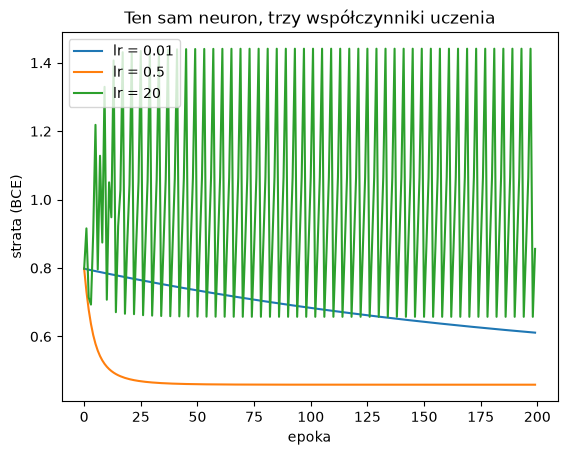

In [15]:
for lr in [0.01, 0.5, 20]:
    torch.manual_seed(42)
    neuron = nn.Sequential(nn.Linear(5, 1), nn.Sigmoid())
    optymalizator = torch.optim.SGD(neuron.parameters(), lr=lr)

    historia = []
    for epoka in range(200):
        optymalizator.zero_grad()
        strata = funkcja_straty(neuron(X_train_t), y_train_t)
        strata.backward()
        optymalizator.step()
        historia.append(strata.item())

    plt.plot(historia, label=f"lr = {lr}")

plt.legend()
plt.title("Ten sam neuron, trzy współczynniki uczenia")
plt.xlabel("epoka")
plt.ylabel("strata (BCE)")

- **lr = 0.01 — za mały.** Strata spada, ale tak wolno, że po 200 epokach model
  jest wciąż daleko od dna. Kroczki po milimetrze.
- **lr = 0.5 — w sam raz.** Szybki spadek i stabilne dno.
- **lr = 20 — za duży.** Pierwszy krok wyrzuca model wyżej, niż zaczął,
  a potem strata skacze w górę i w dół. To prawy wykres ze spadkiem gradientu:
  przeskakiwanie doliny.

> 💡 **Jak dobrać współczynnik uczenia**
>
> Nie zgadujesz w ciemno. Zaczynasz od typowej wartości (dla SGD 0.1 albo
> 0.01), patrzysz na krzywą uczenia i poprawiasz: spada za wolno — zwiększ
> kilkukrotnie, skacze — zmniejsz. Krzywa uczenia to Twój główny przyrząd
> pokładowy.

### Czego jeden neuron nie umie

Neuron liczy **ważoną sumę**, więc umie wyrazić tylko zależności typu „im więcej
X, tym większe (albo mniejsze) ryzyko" — zawsze w tę samą stronę i zawsze
w tym samym tempie. Gdyby ryzyko rezygnacji było duże i przy bardzo małej,
i przy bardzo dużej liczbie wizyt (np. zapaleńcy szybko się wypalają), jedna waga
tego nie zapisze — może być albo dodatnia, albo ujemna.

Na to jest prosta rada: **więcej neuronów**, ułożonych w warstwy. To temat
następnych zajęć.


## Ściągawka

| Chcę… | Kod |
|---|---|
| wagi i bias regresji logistycznej | `model.coef_[0]`, `model.intercept_[0]` |
| wagi z nazwami cech | `pd.Series(model.coef_[0], index=cechy)` |
| sigmoida w numpy | `1 / (1 + np.exp(-z))` |
| ważona suma dla wszystkich naraz | `X_s @ w + b` |
| strata logarytmiczna | `log_loss(y, p)` (scikit-learn), `nn.BCELoss()` (PyTorch) |
| DataFrame / numpy → tensor | `torch.tensor(X_s, dtype=torch.float32)` |
| etykiety jako kolumna | `torch.tensor(y.values, dtype=torch.float32).view(-1, 1)` |
| jeden neuron | `nn.Sequential(nn.Linear(liczba_cech, 1), nn.Sigmoid())` |
| powtarzalne losowanie | `torch.manual_seed(42)` |
| optymalizator | `torch.optim.SGD(model.parameters(), lr=0.5)` |
| pętla treningowa | `zero_grad()` → `p = model(X)` → `strata = f(p, y)` → `backward()` → `step()` |
| zapamiętać stratę | `historia.append(strata.item())` |
| przewidywania bez treningu | `with torch.no_grad(): p = model(X_t).numpy().ravel()` |
| klasy z prawdopodobieństw | `(p > 0.5).astype(int)` |
| wagi z modelu PyTorch | `model[0].weight.detach().numpy()[0]`, `model[0].bias.item()` |

## Zadanie 4

Treść zadania na dzisiejsze zajęcia znajdziesz w [notatkach](https://kubzal.github.io/wsb-merito/semestr_zimowy_2026_27/uczenie_glebokie/zajecia_4/#zadanie-4-neuron-ocenia-wnioski-kredytowe-6-pkt). Rozwiązanie zrób w **osobnym** notebooku i oddaj go na Moodle.